In [35]:
# 📊 Retail Diagnostic & Profitability Root-Cause Analysis

### Professional Business Dashboard & Portfolio Project

In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### 1. Data Loading & Initial Inspection

In [27]:
import f_s
df = pd.read_feather(f_s.f_superstore)

In [28]:
df.info

<bound method DataFrame.info of        Row ID        Order ID Order Date  Ship Date       Ship Mode  \
0           1  US-2023-103800 2023-01-03 2023-01-07  Standard Class   
1           2  US-2023-112326 2023-01-04 2023-01-08  Standard Class   
2           3  US-2023-112326 2023-01-04 2023-01-08  Standard Class   
3           4  US-2023-112326 2023-01-04 2023-01-08  Standard Class   
4           5  US-2023-141817 2023-01-05 2023-01-12  Standard Class   
...       ...             ...        ...        ...             ...   
10189   10190  US-2026-143259 2026-12-30 2027-01-03  Standard Class   
10190   10191  US-2026-115427 2026-12-30 2027-01-03  Standard Class   
10191   10192  US-2026-156720 2026-12-30 2027-01-03  Standard Class   
10192   10193  US-2026-143259 2026-12-30 2027-01-03  Standard Class   
10193   10194  CA-2026-143500 2026-12-30 2027-01-03  Standard Class   

      Customer ID      Customer Name      Segment Country/Region  \
0        DP-13000      Darren Powers     Consum

## 1. High-Level Performance Overview
Initial aggregation by product category to establish baseline sales and profitability trends across the business.

In [29]:
best_profit = df.groupby('Category')[['Sales', 'Profit']].sum().sort_values(by='Profit', ascending=False)
best_profit

,Sales,Profit
Category,,
Technology,839893.2790,146543.3756
Office Supplies,731893.3140,126023.4434
Furniture,754747.7613,19729.9956


In [30]:
best_profit = df.groupby(['Category', 'Sub-Category'])['Profit'].sum().sort_values()
best_profit

Category         Sub-Category
Furniture        Tables         -17753.2061
                 Bookcases       -3632.0736
Office Supplies  Supplies        -1171.3945
                 Fasteners        2428.6358
Technology       Machines         3461.9769
Office Supplies  Labels           5572.7780
                 Art              6653.1962
                 Envelopes        6988.0247
Furniture        Furnishings     13891.7430
Office Supplies  Appliances      18329.4844
                 Storage         21285.1115
Furniture        Chairs          27223.5323
Office Supplies  Binders         31426.1003
                 Paper           34511.5070
Technology       Accessories     41936.6357
                 Phones          45050.8265
                 Copiers         56093.9365
Name: Profit, dtype: float64

In [31]:
best_profit = df.groupby(['Category', 'Sub-Category'])[['Sales', 'Profit', 'Discount']].mean().sort_values(by='Discount', ascending=False)
best_profit

Sales      Profit  Discount
Category        Sub-Category                                   
Office Supplies Binders        133.950182   20.301098  0.369057
Technology      Machines      1623.290863   29.589546  0.304274
Furniture       Tables         638.098718  -54.457687  0.258129
                Bookcases      497.246570  -15.655490  0.215259
                Chairs         529.602916   42.939325  0.169243
Office Supplies Appliances     228.297859   38.669798  0.164557
Technology      Copiers       2153.504143  801.341950  0.157143
                Phones         367.489081   49.890173  0.152602
Furniture       Furnishings     94.745417   13.767833  0.138057
Office Supplies Envelopes       64.563914   27.296971  0.079688
                Fasteners       37.258690   10.605397  0.078603
Technology      Accessories    215.974604   54.111788  0.078452
Office Supplies Supplies       243.361969   -6.101013  0.076042
                Storage        262.435227   24.865784  0.075117
                Art             33.689420    8.103771  0.075030
                Paper           57.471487   24.936060  0.075000
                Labels          34.497397   15.143418  0.070924

## 2. Root-Cause Diagnostic: Identifying Loss Drivers & Discount Tipping Points
By drilling down from broad categories to sub-categories, we isolate the exact operational leakages (e.g., Tables, Bookcases, Supplies) and evaluate the precise discount thresholds where profitability flips from positive to negative.

In [32]:
# 1. Sub-Category Performance Diagnostic: Identifying root profit/loss drivers
subcat_performance = (
    df.groupby(["Category", "Sub-Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Mean_Discount=("Discount", "mean"),
        Transaction_Count=("Sales", "count"),
    )
    .reset_index()
)

# Isolate loss-making sub-categories
loss_drivers = subcat_performance[subcat_performance["Total_Profit"] < 0].sort_values(
    by="Total_Profit", ascending=True
)
print("--- Loss-Making Sub-Categories ---")
display(loss_drivers)

# 2. Granular Discount Threshold Analysis for Vulnerable Sub-Categories
# Focusing on 'Supplies' and 'Tables' to find the exact profit tipping point
vulnerable_subcats = ["Supplies", "Tables"]
target_df = df[df["Sub-Category"].isin(vulnerable_subcats)]

discount_tipping_point = (
    target_df.groupby(["Sub-Category", "Discount"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit_Per_Order=("Profit", "mean"),
        Order_Count=("Sales", "count"),
    )
    .reset_index()
)

# Filter transactions flipping into negative profit
negative_thresholds = discount_tipping_point[
    discount_tipping_point["Total_Profit"] < 0
]
print("\n--- Discount Tipping Points Causing Net Losses ---")
display(negative_thresholds)

--- Loss-Making Sub-Categories ---


,Category,Sub-Category,Total_Sales,Total_Profit,Mean_Discount,Transaction_Count
3,Furniture,Tables,208020.1820,-17753.2061,0.258129,326
0,Furniture,Bookcases,115361.2043,-3632.0736,0.215259,232
12,Office Supplies,Supplies,46725.4980,-1171.3945,0.076042,192



--- Discount Tipping Points Causing Net Losses ---


,Sub-Category,Discount,Total_Sales,Total_Profit,Average_Profit_Per_Order,Order_Count
1,Supplies,0.20,15114.328,-2907.4937,-39.828681,73
3,Tables,0.20,45636.582,-298.3980,-4.144417,72
4,Tables,0.30,25902.980,-3493.8376,-62.389957,56
5,Tables,0.40,45614.406,-16187.3968,-215.831957,75
6,Tables,0.45,5484.974,-2493.1111,-226.646464,11
7,Tables,0.50,13675.010,-8615.3873,-239.316314,36


### 3. Root-Cause Diagnostic: Identifying Loss Drivers & Discount Tipping Points
By drilling down from broad categories to sub-categories, we isolate the exact operational leakages (e.g., Tables, Bookcases, Supplies) and evaluate the precise discount thresholds where profitability flips from positive to negative.

In [33]:
# 3. Geographic Drill-Down: Identifying high-loss states and cities for vulnerable sub-categories
vulnerable_subcats = ["Tables", "Bookcases", "Supplies"]
loss_df = df[df["Sub-Category"].isin(vulnerable_subcats) & (df["Profit"] < 0)]

geo_loss_analysis = (
    loss_df.groupby(["State/Province", "City", "Sub-Category"])
    .agg(
        Total_Loss=("Profit", "sum"), Loss_Transaction_Count=("Profit", "count")
    )
    .reset_index()
    .sort_values(by="Total_Loss", ascending=True)
)  # Most negative profit first

print("--- Top Loss-Making Locations ---")
display(geo_loss_analysis.head(15))

# 4. Product-Level Drill-Down: Finding exact products driving the losses
product_loss_analysis = (
    loss_df.groupby(["Sub-Category", "Product Name"])
    .agg(
        Total_Loss=("Profit", "sum"), Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values(by="Total_Loss", ascending=True)
)

print("\n--- Top Loss-Making Products ---")
display(product_loss_analysis.head(15))

--- Top Loss-Making Locations ---


,State/Province,City,Sub-Category,Total_Loss,Loss_Transaction_Count
79,New York,New York City,Tables,-3542.7216,23
127,Pennsylvania,Philadelphia,Tables,-2588.7538,15
125,Pennsylvania,Philadelphia,Bookcases,-2568.1413,8
86,North Carolina,Concord,Tables,-1862.3124,1
6,Arizona,Phoenix,Tables,-1491.9276,4
61,Illinois,Chicago,Tables,-1446.9305,8
126,Pennsylvania,Philadelphia,Supplies,-1364.8876,4
56,Illinois,Aurora,Tables,-1255.8546,5
137,Tennessee,Knoxville,Tables,-1150.6491,2
152,Texas,Houston,Bookcases,-1120.4223,12



--- Top Loss-Making Products ---


,Sub-Category,Product Name,Total_Loss,Units_Sold
83,Tables,Chromcraft Bull-Nose Wood Oval Conference Tabl...,-3107.5272,24
77,Tables,Bush Advantage Collection Racetrack Conference...,-2545.2600,25
31,Bookcases,"Riverside Palais Royal Lawyers Bookcase, Royal...",-1982.2050,11
59,Tables,Balt Solid Wood Round Tables,-1522.5309,11
49,Supplies,Martin Yale Chadless Opener Electric Letter Op...,-1499.0580,10
65,Tables,"Bevis Oval Conference Table, Walnut",-1344.0470,25
75,Tables,Bretford Rectangular Conference Table Tops,-1211.1404,21
105,Tables,"Riverside Furniture Oval Coffee Table, Oval En...",-1210.5070,24
72,Tables,BoxOffice By Design Rectangular and Half-Moon ...,-1148.4375,15
76,Tables,Bretford “Just In Time” Height-Adjustable Mult...,-1081.0660,13


### 4. Granular Drill-Down: Geographic & Product-Level Localization
To ensure actionable business insights, we analyze whether losses are systemic or localized by pinpointing specific high-loss metropolitan areas (e.g., New York City, Philadelphia) and specific product SKUs.

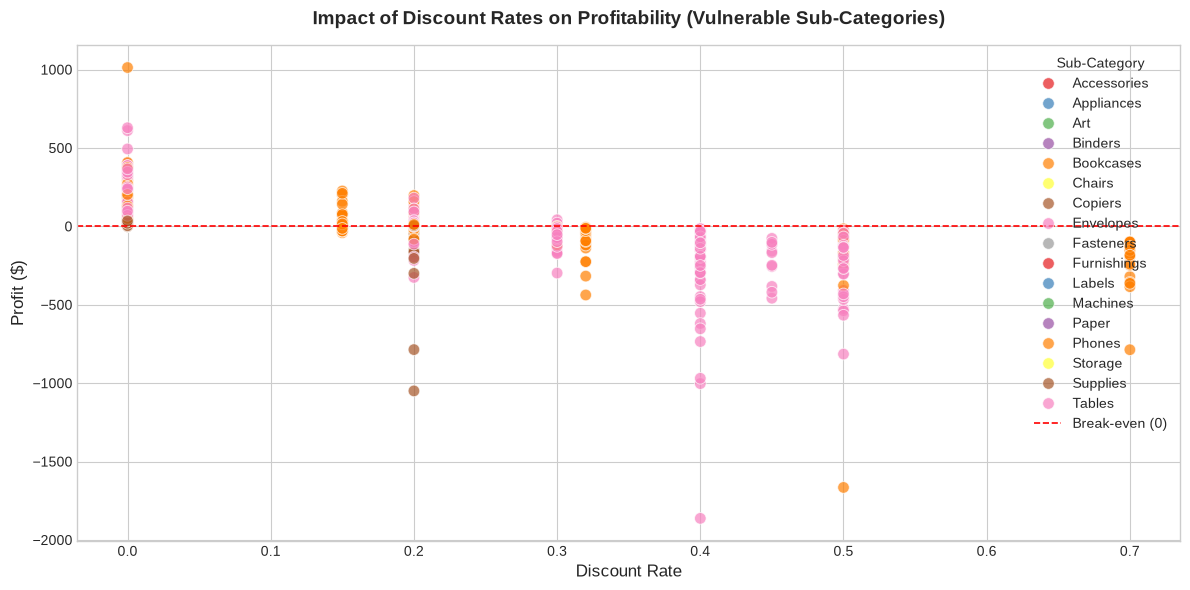

In [34]:
# Set professional plotting style
plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(12, 6))

# 1. Visualization: Discount vs Total Profit for Vulnerable Sub-Categories
vulnerable_subcats = ["Tables", "Bookcases", "Supplies"]
plot_data = df[df["Sub-Category"].isin(vulnerable_subcats)]

ax = sns.scatterplot(
    data=plot_data,
    x="Discount",
    y="Profit",
    hue="Sub-Category",
    palette="Set1",
    alpha=0.7,
    s=70,
)

plt.axhline(0, color="red", linestyle="--", linewidth=1.2, label="Break-even (0)")
plt.title(
    "Impact of Discount Rates on Profitability (Vulnerable Sub-Categories)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Discount Rate", fontsize=12)
plt.ylabel("Profit ($)", fontsize=12)
plt.legend(title="Sub-Category")
plt.tight_layout()
plt.savefig('ImpactofDiscount.png')
plt.show()

### 💡 Executive Summary & Strategic Recommendations

Based on the diagnostic analysis of loss-making drivers in the Superstore dataset, we recommend the following targeted interventions rather than blanket operational changes:

1. **Enforce Strict Discount Caps on High-Risk Categories:**
   * **Tables & Bookcases:** Data indicates that discounts exceeding 20% consistently flip transactions into negative profit margins. Implement an automated approval workflow in the CRM/ERP system for any discount above 15% on these items.
   * **Supplies:** Operating on an extremely narrow margin, even low discounts (~7-8%) erode profitability. Re-evaluate baseline pricing and shipping overheads for low-cost office supplies.

2. **Geographic Sales Audits:**
   * High-loss transactions are heavily concentrated in key metropolitan areas such as **New York City** and **Philadelphia**. Conduct a localized logistics and fulfillment cost audit to determine if high shipping or handling fees are driving these regional losses.

3. **Product-Level Portfolio Optimization:**
   * Phase out or re-negotiate vendor contracts for extreme loss-making products (e.g., *Chromcraft Bull-Nose Wood Oval Conference Table*), which generate disproportionate financial leakage relative to units sold.